# Simulation-Based SOTIF Validation

**Module 04 · SOTIF (ISO 21448)** · Notebook 4 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/04_simulation_based_validation.ipynb) [![Run in browser](https://img.shields.io/badge/Run_in_browser-no_account-0072B2)](https://milinpatel07.github.io/Autonomous-Driving_AI-Safety-and-Security/lite/notebooks/index.html?path=04_SOTIF_ISO21448/04_simulation_based_validation.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [01 · SOTIF fundamentals](01_sotif_fundamentals.ipynb), [02 · Triggering conditions and scenarios](02_triggering_conditions_and_scenarios.ipynb) | ISO 21448:2022, ISO 26262-8:2018, Regulation (EU) 2022/1426 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Explain the role of simulation in the evaluation of known and unknown scenarios (ISO 21448 clauses 10–11)
- Structure a simulation campaign over weather and time of day, following the author's CARLA-based SOTIF use case
- Trace perception metrics to vehicle-level acceptance criteria instead of treating AP thresholds as 'ISO criteria'
- Assess **simulation credibility**: sim-to-real gap, tool confidence (ISO 26262-8), credibility assessment of virtual toolchains
- Estimate a rare failure probability with **importance sampling** and compare it with naive Monte Carlo
- Distinguish **coverage-oriented** from **distribution-oriented** scenario sampling

In [1]:
# Setup — pure NumPy/SciPy; no simulator installation is needed for this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate

rng = np.random.default_rng(42)
OI = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442',
      'blue': '#0072B2', 'vermillion': '#D55E00', 'purple': '#CC79A7', 'grey': '#999999', 'black': '#000000'}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete.")

Setup complete.


## 1. Simulation in SOTIF validation

Simulation contributes to ISO 21448 in two ways:

- **Evaluation of known scenarios** (clause 10): run the identified triggering conditions and their combinations
  systematically, including those too dangerous for the road.
- **Evaluation of unknown scenarios** (clause 11): explore large scenario spaces, search for hazardous regions
  (falsification), and estimate rates of hazardous behaviour with rare-event methods.

Two kinds of simulation are common:

| Kind | What is simulated | Typical use | Example |
|---|---|---|---|
| **Open loop** (sensor/perception) | Sensor data under varied conditions; the perception output is evaluated | Performance insufficiencies of perception under triggering conditions | LiDAR point clouds for 3D object detection under 21 weather/time settings (Patel & Jung, 2024) |
| **Closed loop** (behaviour) | The vehicle's reactions change the scene | Hazardous behaviour at vehicle level; criticality metrics | Cut-in scenarios with the planning and control stack in the loop |

### Simulation platforms (as of October 2026)

| Platform | Type | Notes |
|---|---|---|
| **CARLA** | Open-source driving simulator (Unreal Engine) | Developed at CVC Barcelona with industry support; Python API, camera/LiDAR/radar sensors, ScenarioRunner for OpenSCENARIO (Dosovitskiy et al., 2017) |
| **esmini** | Open-source ASAM OpenSCENARIO XML player | Lightweight scenario execution and visualisation |
| **Eclipse SUMO** | Open-source **microscopic traffic-flow** simulation (DLR) | Simulates traffic, not sensors; often co-simulated with CARLA (Lopez et al., 2018) |
| **Scenic** | Probabilistic scenario-description language | Generates scenes/scenarios for simulators such as CARLA (Fremont et al., 2019) |
| Commercial tools | e.g. IPG CarMaker, dSPACE AURELION, Siemens Simcenter Prescan | Physics-based sensor models, HiL integration |
| *LGSVL / SVL* | *Historical* | Development suspended by LG in 2022 |
| *AirSim (Microsoft)* | *Historical* | Archived by Microsoft |

None of these needs to be installed for this notebook; all computations below use small, transparent models.

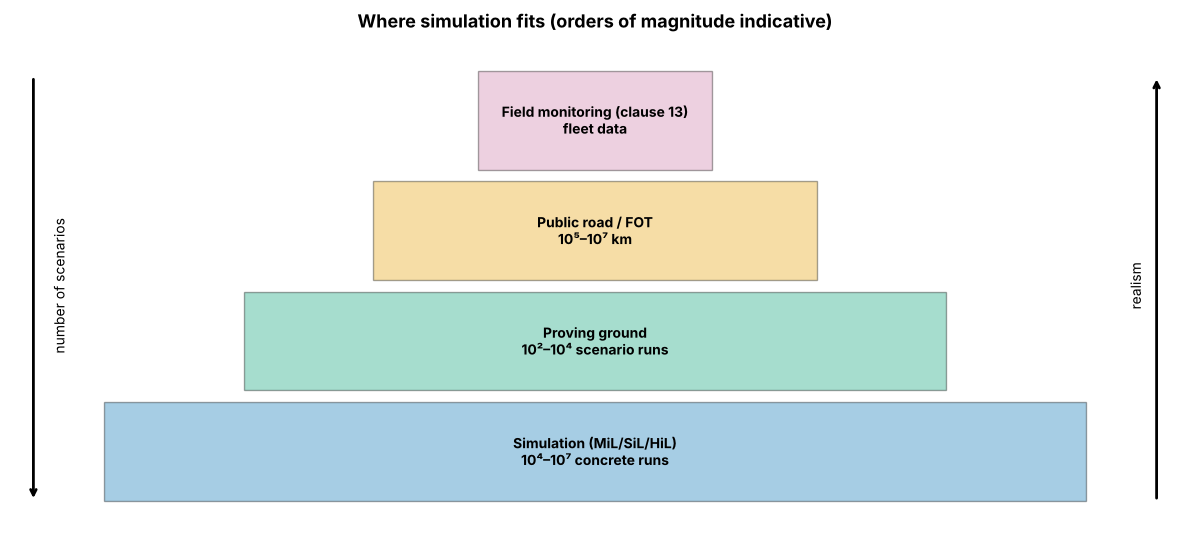

In [2]:
def visualize_test_environments():
    fig, ax = plt.subplots(figsize=(12, 5.5))
    levels = [('Simulation (MiL/SiL/HiL)\n10⁴–10⁷ concrete runs', 0.84, OI['blue']),
              ('Proving ground\n10²–10⁴ scenario runs', 0.60, OI['green']),
              ('Public road / FOT\n10⁵–10⁷ km', 0.38, OI['orange']),
              ('Field monitoring (clause 13)\nfleet data', 0.20, OI['purple'])]
    y = 0.05
    for label, width, col in levels:
        ax.add_patch(plt.Rectangle((0.5 - width / 2, y), width, 0.17, facecolor=col, alpha=0.35, edgecolor='black'))
        ax.text(0.5, y + 0.085, label, ha='center', va='center', fontsize=10, fontweight='bold')
        y += 0.19
    ax.annotate('', xy=(0.02, 0.05), xytext=(0.02, 0.78), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(0.035, 0.42, 'number of scenarios', rotation=90, va='center')
    ax.annotate('', xy=(0.98, 0.78), xytext=(0.98, 0.05), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(0.955, 0.42, 'realism', rotation=90, va='center')
    ax.set_xlim(0, 1); ax.set_ylim(0, 0.85); ax.axis('off')
    ax.set_title('Where simulation fits (orders of magnitude indicative)', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_test_environments()

## 2. A SOTIF-related simulation use case

Patel & Jung (2024) defined a SOTIF-related use case in **CARLA**: an ego vehicle with a LiDAR sensor, **21 weather
conditions** combining clear, cloudy and rainy weather with **noon, sunset and night**, and a resulting LiDAR dataset
of **547 frames** (published as *SOTIF PCOD* on IEEE DataPort). Pre-trained 3D object detectors from the MMDetection3D
and OpenPCDet toolkits were evaluated with Average Precision and Recall. The 21 conditions correspond to CARLA's seven
weather presets at three times of day (preset names such as `ClearNoon`, `WetSunset`, `HardRainNight`).

The test matrix below reproduces this structure. Real results are in the paper; this notebook does not reproduce them.

In [3]:
weathers = ['Clear', 'Cloudy', 'Wet', 'WetCloudy', 'SoftRain', 'MidRain', 'HardRain']
times = ['Noon', 'Sunset', 'Night']
matrix = pd.DataFrame([{'ID': f'W{i:02d}', 'Weather': w, 'Time': t, 'CARLA preset (pattern)': f'{w}{t}'}
                       for i, (w, t) in enumerate(((w, t) for w in weathers for t in times), start=1)])
print(f"Test matrix: {len(weathers)} weather presets × {len(times)} times of day = {len(matrix)} conditions")
display(matrix.pivot(index='Weather', columns='Time', values='ID').loc[weathers, times])

Test matrix: 7 weather presets × 3 times of day = 21 conditions


Time,Noon,Sunset,Night
Weather,,,
Clear,W01,W02,W03
Cloudy,W04,W05,W06
Wet,W07,W08,W09
WetCloudy,W10,W11,W12
SoftRain,W13,W14,W15
MidRain,W16,W17,W18
HardRain,W19,W20,W21


**Optional: the real SOTIF-PCOD data.** The dataset of Patel & Jung (2024) is published on IEEE DataPort
(doi:10.21227/j43q-z578, CC BY 4.0, about 1.84 GB, KITTI-format LiDAR point clouds and labels generated in CARLA).
DataPort requires a (free) login, so the notebook cannot download it. If you have it, set the environment variable
`SOTIF_PCOD_DIR` to the unpacked folder; the cell below then lists the frames and plots one scan. Without it the cell
only explains how to obtain the data and the rest of the notebook runs unchanged.

In [4]:
import os
from pathlib import Path

pcod_dir = Path(os.environ.get('SOTIF_PCOD_DIR', '')).expanduser()
scans = sorted(pcod_dir.rglob('*.bin')) if os.environ.get('SOTIF_PCOD_DIR') and pcod_dir.is_dir() else []
if scans:
    labels = sorted(pcod_dir.rglob('label*/*.txt'))
    print(f"SOTIF-PCOD found at {pcod_dir}: {len(scans)} LiDAR scans, {len(labels)} label files.")
    pts = np.fromfile(scans[0], dtype=np.float32).reshape(-1, 4)          # x, y, z, intensity (KITTI format)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(pts[:, 0], pts[:, 1], s=0.2, c=pts[:, 2], cmap='viridis')
    ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)'); ax.set_aspect('equal')
    ax.set_title(f'{scans[0].name}: {len(pts):,} points', fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print("SOTIF-PCOD not available locally (set SOTIF_PCOD_DIR to use it).\n"
          "Obtain it from IEEE DataPort: https://doi.org/10.21227/j43q-z578 (free account; CC BY 4.0, ~1.84 GB).\n"
          "The sections below use a synthetic performance model with the same 21-condition structure.")

SOTIF-PCOD not available locally (set SOTIF_PCOD_DIR to use it).
Obtain it from IEEE DataPort: https://doi.org/10.21227/j43q-z578 (free account; CC BY 4.0, ~1.84 GB).
The sections below use a synthetic performance model with the same 21-condition structure.


### Sensor physics matters

LiDAR is an **active** sensor: it brings its own light, so darkness does not reduce the return signal (strong sunlight
mainly adds background noise). Rain and spray, in contrast, **attenuate** the beam on the way out and back and add
spurious near-range returns. A simulation campaign is only informative if the simulator's sensor model reproduces the
effects of the triggering conditions under study — something to check, not assume.

> **Illustrative data:** the point clouds below come from a toy model (two-way attenuation $e^{-2\alpha R}$ plus
> random near-range clutter) with made-up attenuation coefficients; they are not CARLA output.

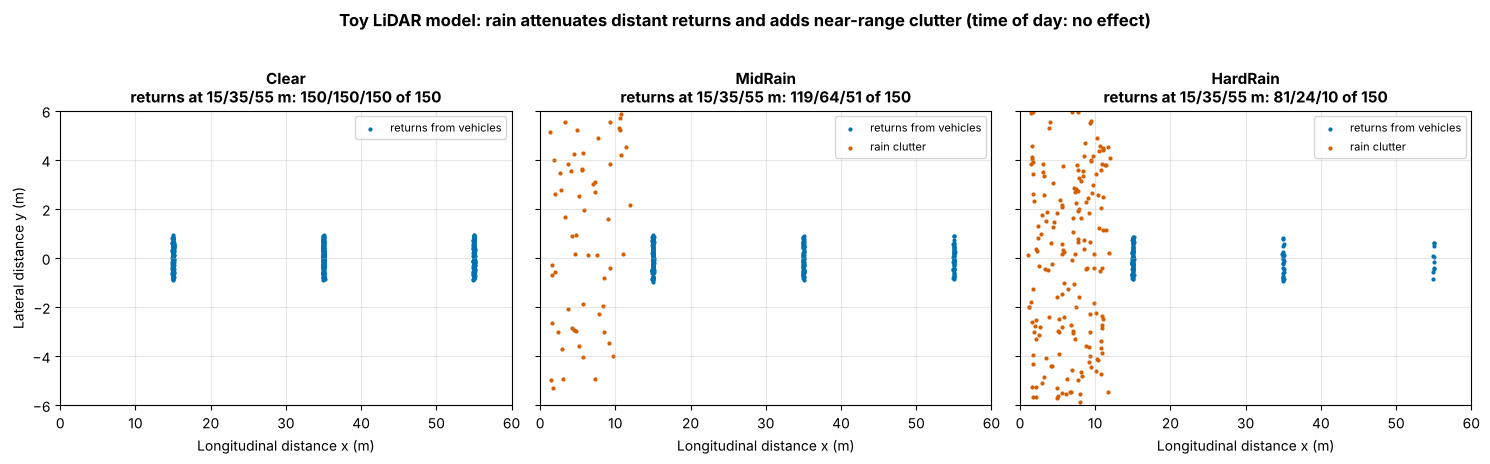

In [5]:
ALPHA = {'Clear': 0.0, 'MidRain': 0.010, 'HardRain': 0.025}         # 1/m, made-up teaching values
CLUTTER = {'Clear': 0, 'MidRain': 60, 'HardRain': 180}              # spurious returns per sweep

def toy_scan(weather, rng):
    """Bird's-eye view of returns from three car-sized boxes at 15, 35 and 55 m, plus rain clutter."""
    pts = []
    for x0 in (15, 35, 55):
        side = np.c_[np.full(150, x0), rng.uniform(-0.9, 0.9, 150)]           # rear face of a car
        pts.append(side + rng.normal(0, 0.05, side.shape))
    pts = np.vstack(pts)
    r = np.linalg.norm(pts, axis=1)
    keep = rng.random(len(pts)) < np.exp(-2 * ALPHA[weather] * r)
    clutter = np.c_[rng.uniform(1, 12, CLUTTER[weather]), rng.uniform(-6, 6, CLUTTER[weather])]
    return pts[keep], clutter

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, w in zip(axes, ALPHA):
    obj, clut = toy_scan(w, rng)
    ax.scatter(obj[:, 0], obj[:, 1], s=4, color=OI['blue'], label='returns from vehicles')
    if len(clut):
        ax.scatter(clut[:, 0], clut[:, 1], s=4, color=OI['vermillion'], label='rain clutter')
    counts = [int(np.sum(np.abs(obj[:, 0] - x0) < 1)) for x0 in (15, 35, 55)]
    ax.set_title(f'{w}\nreturns at 15/35/55 m: {counts[0]}/{counts[1]}/{counts[2]} of 150', fontsize=11, fontweight='bold')
    ax.set_xlabel('Longitudinal distance x (m)'); ax.set_xlim(0, 60); ax.set_ylim(-6, 6)
    ax.legend(loc='upper right', fontsize=8)
axes[0].set_ylabel('Lateral distance y (m)')
plt.suptitle('Toy LiDAR model: rain attenuates distant returns and adds near-range clutter (time of day: no effect)',
             fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

## 3. From detection results to evidence

To practise the evaluation workflow we need per-object detection outcomes for each of the 21 conditions. They come
from a **synthetic performance model**: the probability of detecting an object falls with range, and the range at
which it reaches 50 % shrinks with precipitation. Two hypothetical detectors, A and B, differ only in that range.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements and not results of
> PointPillars, SECOND, PV-RCNN or any other real detector. For real results see Patel & Jung (2024).

Each condition has 200 synthetic ground-truth objects; recall is reported with a 95 % Clopper–Pearson interval so that
small samples are not over-interpreted.

Detector  Detector A              Detector B             
Time           Night  Noon Sunset      Night  Noon Sunset
Weather                                                  
Clear           0.99  0.98   0.96       1.00  0.99   0.99
Cloudy          0.98  0.99   0.98       0.99  1.00   1.00
Wet             0.99  0.99   0.96       1.00  0.99   1.00
WetCloudy       0.97  0.98   0.97       0.99  0.99   1.00
SoftRain        0.90  0.92   0.87       0.99  0.95   0.97
MidRain         0.85  0.86   0.83       0.93  0.88   0.88
HardRain        0.70  0.64   0.64       0.73  0.67   0.76

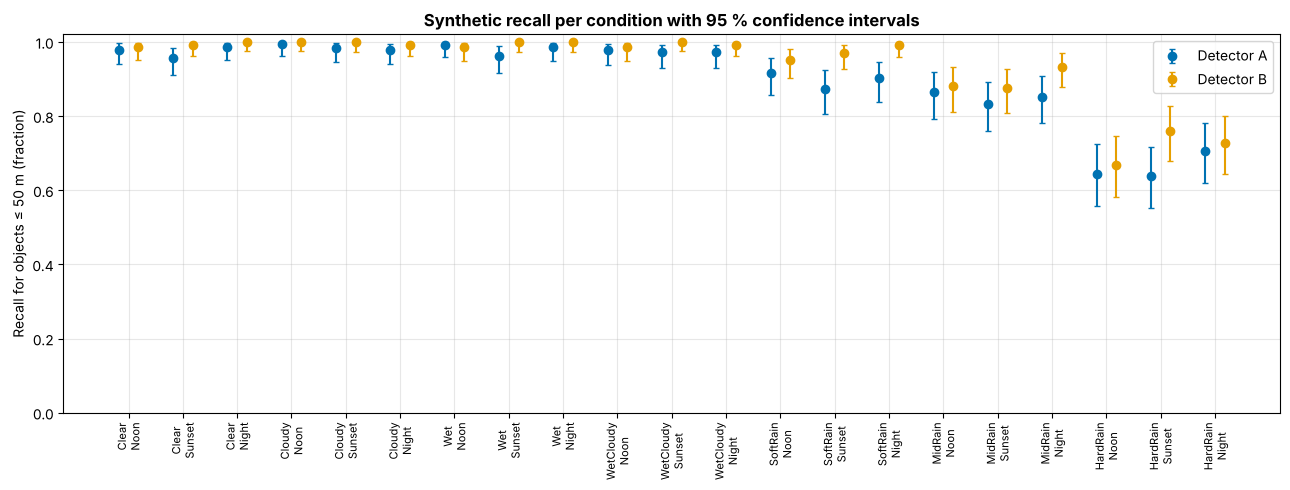

In [6]:
R50 = {'Clear': 62, 'Cloudy': 62, 'Wet': 60, 'WetCloudy': 59, 'SoftRain': 52, 'MidRain': 45, 'HardRain': 36}  # m
TIME_FACTOR = {'Noon': 0.97, 'Sunset': 0.99, 'Night': 1.00}     # small: sunlight adds background noise
DETECTOR_SCALE = {'Detector A': 1.00, 'Detector B': 1.12}
N_OBJ, RANGE_MAX, RELEVANT_RANGE = 200, 70.0, 50.0

def cp_interval(k, n, conf=0.95):
    a = 1 - conf
    lo = 0.0 if k == 0 else stats.beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

rows = []
for _, c in matrix.iterrows():
    ranges = rng.uniform(5, RANGE_MAX, N_OBJ)
    for det, scale in DETECTOR_SCALE.items():
        r50 = R50[c['Weather']] * TIME_FACTOR[c['Time']] * scale
        detected = rng.random(N_OBJ) < 1 / (1 + np.exp((ranges - r50) / 6.0))
        rel = ranges <= RELEVANT_RANGE                        # objects in the function-relevant range
        k, n = int(detected[rel].sum()), int(rel.sum())
        lo, hi = cp_interval(k, n)
        rows.append({'ID': c['ID'], 'Weather': c['Weather'], 'Time': c['Time'], 'Detector': det,
                     'n objects (≤50 m)': n, 'Recall (≤50 m)': k / n, 'CI low': lo, 'CI high': hi})
results = pd.DataFrame(rows)

pivot = results.pivot_table(index='Weather', columns=['Detector', 'Time'], values='Recall (≤50 m)').loc[weathers]
display(pivot.round(2))

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(matrix))
for off, (det, col) in zip((-0.18, 0.18), ((('Detector A'), OI['blue']), ('Detector B', OI['orange']))):
    sub = results[results['Detector'] == det].reset_index(drop=True)
    ax.errorbar(x + off, sub['Recall (≤50 m)'], yerr=[sub['Recall (≤50 m)'] - sub['CI low'],
                sub['CI high'] - sub['Recall (≤50 m)']], fmt='o', color=col, capsize=2, label=det)
ax.set_xticks(x); ax.set_xticklabels(matrix['Weather'] + '\n' + matrix['Time'], rotation=90, fontsize=8)
ax.set_ylabel('Recall for objects ≤ 50 m (fraction)'); ax.set_ylim(0, 1.02)
ax.set_title('Synthetic recall per condition with 95 % confidence intervals', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

### Acceptance criteria are vehicle-level

ISO 21448 prescribes **no** AP or recall thresholds. Its acceptance criteria concern the **residual risk of hazardous
behaviour at vehicle level** (e.g. a maximum rate of a hazardous behaviour per hour), and validation targets are
derived from them (see [Notebook 01](01_sotif_fundamentals.ipynb), Section 6). Perception thresholds are at most
**derived requirements** that must be traced to those criteria through the function's architecture — e.g. "with
radar fusion and the braking strategy, a camera/LiDAR recall of ≥ 85 % within 50 m keeps the rate of missed
pedestrian brakings below the acceptance criterion".

Below, each condition is judged against such an illustrative derived requirement, with three outcomes so that
statistical uncertainty is respected. Conditions that clearly fail are **candidate triggering conditions**: a recall
drop is a performance insufficiency at component level, and whether it leads to **hazardous behaviour** must be
confirmed in closed-loop evaluation.

In [7]:
REQ_RECALL = 0.85    # illustrative derived perception requirement (not an ISO 21448 value)

def verdict(row):
    if row['CI low'] >= REQ_RECALL:
        return 'meets'
    if row['CI high'] < REQ_RECALL:
        return 'does not meet'
    return 'inconclusive'

results['Verdict'] = results.apply(verdict, axis=1)
summary = results.pivot_table(index='Detector', columns='Verdict', values='ID', aggfunc='count', fill_value=0)
display(summary)

cand = results[results['Verdict'] == 'does not meet']
cand_conditions = cand.groupby(['Weather', 'Time'])['Detector'].apply(lambda s: ', '.join(sorted(s))).reset_index()
print("Candidate triggering conditions (recall clearly below the derived requirement) — confirm in closed loop:")
display(cand_conditions)
incon = results[results['Verdict'] == 'inconclusive']
print(f"Text summary: {len(cand_conditions)} of {len(matrix)} conditions are candidate triggering conditions for at "
      f"least one detector, all with weather in {sorted(cand['Weather'].unique())}; {len(incon)} detector–condition "
      f"pairs are inconclusive and need more samples. Candidates per time of day: {cand_conditions['Time'].value_counts().to_dict()}.")

Verdict,does not meet,inconclusive,meets
Detector,,,
Detector A,3,5,13
Detector B,3,2,16


Candidate triggering conditions (recall clearly below the derived requirement) — confirm in closed loop:


,Weather,Time,Detector
0,HardRain,Night,"Detector A, Detector B"
1,HardRain,Noon,"Detector A, Detector B"
2,HardRain,Sunset,"Detector A, Detector B"


Text summary: 3 of 21 conditions are candidate triggering conditions for at least one detector, all with weather in ['HardRain']; 7 detector–condition pairs are inconclusive and need more samples. Candidates per time of day: {'Night': 1, 'Noon': 1, 'Sunset': 1}.


## 4. Simulation credibility

Simulation evidence counts only as far as the simulation is **credible** for the question asked. The main threats:

- **Sim-to-real gap in sensor models** — rendering and ray-casting omit effects such as multipath, beam divergence,
  rain scattering, motion blur or lens flare; detectors trained on real data may react differently to synthetic data.
- **Behaviour models** of other road users that are too benign or too regular.
- **Numerical and integration issues** — time steps, synchronisation, non-determinism between runs.
- **Parameter distributions** that do not represent real exposure (which matters for every rate estimate).

Recognised approaches:

| Approach | Content |
|---|---|
| **Tool confidence — ISO 26262-8:2018, clause 11** | Classify each software tool by *tool impact* (TI1/TI2) and *tool error detection* (TD1–TD3) → *tool confidence level* TCL1–TCL3; qualify TCL2/TCL3 tools (increased confidence from use, evaluation of the tool development process, validation of the tool, development to a safety standard). Written for tools in E/E development; widely applied to simulation tools by analogy. |
| **Model V&V and uncertainty quantification** | Verify the code, validate the models against measurements, quantify model-form and parameter uncertainty (survey: Riedmaier et al., 2021). |
| **Credibility assessment of virtual toolchains — Regulation (EU) 2022/1426** | For the type-approval of ADS of fully automated vehicles, Annex III Part 4 sets principles for the credibility assessment of a virtual toolchain used in ADS validation (as of October 2026). |
| **Credible Simulation Process** | Process framework from the German SET Level project (2019–2022) for planning, executing and documenting credible simulation. |

ISO 26262-8 tool qualification answers *"can the tool introduce or mask errors?"*. For SOTIF the second question is
equally important: *"does the simulation reproduce the triggering conditions and the system's response to them?"* —
which is answered by validation of the models against real data.

In [8]:
def tool_confidence_level(ti: int, td: int) -> str:
    """ISO 26262-8:2018 clause 11: TI1 → TCL1; TI2 with TD1/TD2/TD3 → TCL1/TCL2/TCL3."""
    if ti not in (1, 2) or td not in (1, 2, 3):
        raise ValueError("TI must be 1 or 2, TD 1–3")
    return 'TCL1' if ti == 1 else f'TCL{td}'

examples = [
    ('Scenario generator feeding a simulator; outputs reviewed and replayed on proving ground', 2, 1),
    ('Simulator whose pass/fail verdicts directly support release, no independent check', 2, 3),
    ('Plotting script for test reports', 1, 3),
]
display(pd.DataFrame([{'Use of tool': u, 'TI': f'TI{ti}', 'TD': f'TD{td}', 'TCL': tool_confidence_level(ti, td)}
                      for u, ti, td in examples]))

,Use of tool,TI,TD,TCL
0,Scenario generator feeding a simulator; output...,TI2,TD1,TCL1
1,Simulator whose pass/fail verdicts directly su...,TI2,TD3,TCL3
2,Plotting script for test reports,TI1,TD3,TCL1


### A sim-to-real correlation check

A practical credibility argument compares simulation with real measurements for a subset of conditions that can be
reproduced on a proving ground, and limits simulation evidence to conditions where they agree within a tolerance.

> **Illustrative data:** the "real" measurements below are synthetic, generated from a deliberately different model in
> which rain degrades detection more strongly than the simulator predicts.

In [9]:
REAL_R50 = dict(R50, MidRain=40, HardRain=28)        # 'reality' differs from the simulator in rain
TOLERANCE = 0.05                                      # acceptable |sim - real| recall difference (illustrative)
check = [('Clear', 'Noon'), ('Cloudy', 'Sunset'), ('MidRain', 'Noon'), ('HardRain', 'Noon'), ('Clear', 'Night')]

rows = []
for w, t in check:
    sim = results[(results['Weather'] == w) & (results['Time'] == t) & (results['Detector'] == 'Detector A')].iloc[0]
    ranges = rng.uniform(5, RELEVANT_RANGE, 150)
    det = rng.random(150) < 1 / (1 + np.exp((ranges - REAL_R50[w] * TIME_FACTOR[t]) / 6.0))
    real = det.mean()
    diff = sim['Recall (≤50 m)'] - real
    se = np.sqrt(sim['Recall (≤50 m)'] * (1 - sim['Recall (≤50 m)']) / sim['n objects (≤50 m)'] + real * (1 - real) / 150)
    lo, hi = diff - 1.96 * se, diff + 1.96 * se
    status = ('agrees' if max(abs(lo), abs(hi)) <= TOLERANCE else
              'disagrees' if min(abs(lo), abs(hi)) > TOLERANCE and lo * hi > 0 else 'inconclusive')
    rows.append({'Condition': f'{w}{t}', 'Sim recall': sim['Recall (≤50 m)'], 'Real recall': real,
                 'Difference (95 % CI)': f'{diff:+.2f} [{lo:+.2f}, {hi:+.2f}]', 'Status': status})
corr = pd.DataFrame(rows)
display(corr.round(2))
print("Text summary:", "; ".join(f"{r['Condition']}: {r['Status']}" for _, r in corr.iterrows()),
      f"(tolerance ±{TOLERANCE}). Simulation evidence should not be used unadjusted where the status is not 'agrees'.")
misleading = corr[(corr['Sim recall'] >= REQ_RECALL) & (corr['Real recall'] < REQ_RECALL)]['Condition'].tolist()
print("Conditions where simulation suggests the derived requirement is met but the real measurement does not:",
      misleading if misleading else "none")

,Condition,Sim recall,Real recall,Difference (95 % CI),Status
0,ClearNoon,0.98,0.99,"-0.01 [-0.04, +0.02]",agrees
1,CloudySunset,0.98,0.99,"-0.00 [-0.03, +0.03]",agrees
2,MidRainNoon,0.86,0.71,"+0.15 [+0.06, +0.24]",disagrees
3,HardRainNoon,0.64,0.49,"+0.16 [+0.04, +0.27]",inconclusive
4,ClearNight,0.99,0.97,"+0.01 [-0.02, +0.04]",agrees


Text summary: ClearNoon: agrees; CloudySunset: agrees; MidRainNoon: disagrees; HardRainNoon: inconclusive; ClearNight: agrees (tolerance ±0.05). Simulation evidence should not be used unadjusted where the status is not 'agrees'.
Conditions where simulation suggests the derived requirement is met but the real measurement does not: ['MidRainNoon']


## 5. Rare events: importance sampling

Hazardous outcomes are rare, so naive Monte Carlo sampling of naturalistic scenarios wastes almost all runs. Take a
**cut-in** on a motorway: another vehicle cuts in at gap $g$ with closing speed $\Delta v$. With system reaction time
$\tau$ and deceleration $a$, a collision (the hazardous behaviour, in this simplified model) occurs if

$$g < \Delta v\,\tau + \frac{\Delta v^2}{2a}, \qquad \Delta v > 0.$$

**Importance sampling** draws from a proposal $q$ concentrated on the critical region and corrects with the weights
$w = p/q$:

$$\hat P = \frac{1}{N}\sum_{i=1}^{N} w(x_i)\,\mathbb{1}[\text{collision}(x_i)], \qquad x_i \sim q .$$

This is the idea behind accelerated evaluation (Zhao et al., 2017); learning-based variants such as dense
reinforcement learning (Feng et al., 2023) push the same principle further.

> **Illustrative data:** the naturalistic distributions and vehicle parameters below are teaching values, not fitted
> to real traffic data. In this 2-D toy problem the exact probability can be computed by numerical integration, so
> both estimators can be checked.

In [10]:
# Naturalistic model (teaching values)
DV_MU, DV_SD = 2.0, 1.5          # closing speed at cut-in, m/s (normal)
G_MED, G_S = 25.0, 0.5           # gap at cut-in, m (lognormal: median, log-sd)
TAU, A_BRAKE = 0.3, 6.0          # system reaction time (s), deceleration (m/s^2)

def required_gap(dv):
    return np.where(dv > 0, dv * TAU + dv ** 2 / (2 * A_BRAKE), 0.0)

def collision(dv, g):
    return g < required_gap(dv)

p_nat = lambda dv, g: stats.norm.pdf(dv, DV_MU, DV_SD) * stats.lognorm.pdf(g, G_S, scale=G_MED)

# Exact value: integrate P(g < required_gap(dv)) over the closing-speed distribution
P_exact, _ = integrate.quad(lambda dv: stats.norm.pdf(dv, DV_MU, DV_SD) *
                            stats.lognorm.cdf(required_gap(dv), G_S, scale=G_MED), 0, 30, points=[5, 10, 15])

# Proposal concentrated on fast, close cut-ins
Q_DV, Q_DV_SD, Q_G_MED, Q_G_S = 8.0, 2.5, 12.0, 0.6
q_prop = lambda dv, g: stats.norm.pdf(dv, Q_DV, Q_DV_SD) * stats.lognorm.pdf(g, Q_G_S, scale=Q_G_MED)

def naive_mc(N, rng):
    dv, g = rng.normal(DV_MU, DV_SD, N), rng.lognormal(np.log(G_MED), G_S, N)
    y = collision(dv, g).astype(float)
    return y.mean(), y.std(ddof=1) / np.sqrt(N), int(y.sum())

def importance_sampling(N, rng):
    dv, g = rng.normal(Q_DV, Q_DV_SD, N), rng.lognormal(np.log(Q_G_MED), Q_G_S, N)
    y = collision(dv, g) * p_nat(dv, g) / q_prop(dv, g)
    return y.mean(), y.std(ddof=1) / np.sqrt(N), int(collision(dv, g).sum())

rows = []
for N in (10**3, 10**4, 10**5):
    for name, f in (('Naive Monte Carlo', naive_mc), ('Importance sampling', importance_sampling)):
        est, se, hits = f(N, rng)
        rows.append({'Method': name, 'N runs': N, 'Collisions observed': hits, 'Estimate': est,
                     '95 % CI half-width': 1.96 * se, 'Relative error': (1.96 * se / est) if est > 0 else np.inf})
rare = pd.DataFrame(rows)
display(rare.style.format({'Estimate': '{:.2e}', '95 % CI half-width': '{:.1e}', 'Relative error': '{:.2f}'}))

# Runs needed for ±10 % relative half-width
is_est, is_se, _ = importance_sampling(10**5, rng)
n_is = (1.96 * is_se * np.sqrt(10**5) / (0.1 * is_est)) ** 2
n_mc = 1.96 ** 2 * (1 - P_exact) / (0.1 ** 2 * P_exact)
print(f"Exact probability per cut-in: {P_exact:.2e}")
print(f"Text summary: for ±10 % relative precision naive Monte Carlo needs about {n_mc:,.0f} runs, importance "
      f"sampling about {n_is:,.0f} runs (≈{n_mc / n_is:,.0f}× fewer).")

,Method,N runs,Collisions observed,Estimate,95 % CI half-width,Relative error
0,Naive Monte Carlo,1000,0,0.00e+00,0.0e+00,inf
1,Importance sampling,1000,252,9.80e-06,4.9e-06,0.50
2,Naive Monte Carlo,10000,0,0.00e+00,0.0e+00,inf
3,Importance sampling,10000,2703,9.78e-06,1.5e-06,0.15
4,Naive Monte Carlo,100000,1,1.00e-05,2.0e-05,1.96
5,Importance sampling,100000,27210,9.37e-06,4.8e-07,0.05


Exact probability per cut-in: 9.43e-06
Text summary: for ±10 % relative precision naive Monte Carlo needs about 40,747,164 runs, importance sampling about 25,969 runs (≈1,569× fewer).


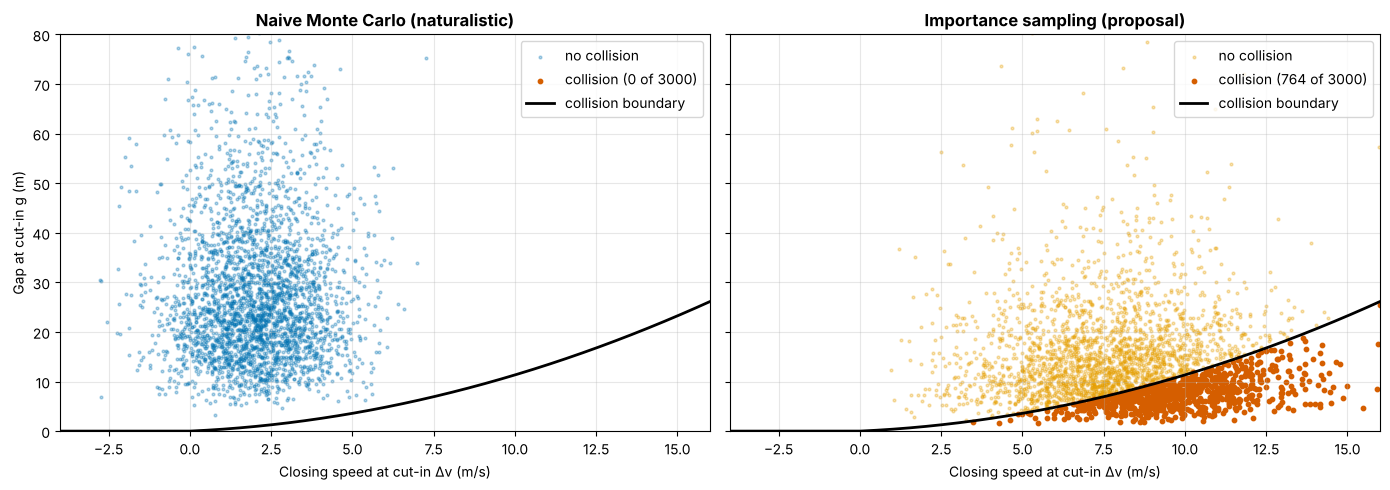

In [11]:
# Where the samples fall: naturalistic vs proposal, with the collision boundary
dv_grid = np.linspace(-4, 16, 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (title, sampler, col) in zip(axes, (
        ('Naive Monte Carlo (naturalistic)', lambda n: (rng.normal(DV_MU, DV_SD, n), rng.lognormal(np.log(G_MED), G_S, n)), OI['blue']),
        ('Importance sampling (proposal)', lambda n: (rng.normal(Q_DV, Q_DV_SD, n), rng.lognormal(np.log(Q_G_MED), Q_G_S, n)), OI['orange']))):
    dv, g = sampler(3000)
    hit = collision(dv, g)
    ax.scatter(dv[~hit], g[~hit], s=4, alpha=0.3, color=col, label='no collision')
    ax.scatter(dv[hit], g[hit], s=10, color=OI['vermillion'], label=f'collision ({hit.sum()} of 3000)')
    ax.plot(dv_grid, required_gap(dv_grid), color=OI['black'], lw=2, label='collision boundary')
    ax.set_xlim(-4, 16); ax.set_ylim(0, 80)
    ax.set_xlabel('Closing speed at cut-in Δv (m/s)'); ax.set_title(title, fontweight='bold'); ax.legend(loc='upper right')
axes[0].set_ylabel('Gap at cut-in g (m)')
plt.tight_layout(); plt.show()

Cautions that belong in any rare-event argument:

- The estimate is only as good as the **naturalistic model** $p$: it must be fitted to representative traffic data
  for the ODD. Importance sampling changes the efficiency, not the dependence on $p$.
- The proposal must cover **all** failure regions. A proposal that misses one gives a biased estimate with a
  deceptively small confidence interval.
- The toy "system" here is two parameters; a real campaign runs the full perception–planning–control stack in closed
  loop, with criticality metrics such as TTC or required deceleration (see
  [05 · Criticality metrics and RSS](05_criticality_metrics_and_rss.ipynb)).

### From a probability per encounter to a rate per hour

A probability per cut-in becomes a rate of hazardous behaviour once multiplied by the **exposure** — how often such
encounters occur per hour in the ODD — and can then be compared with the acceptance criterion from Notebook 01.

In [12]:
CUTINS_PER_HOUR = 1.5        # illustrative exposure in the ODD
LAMBDA_AC = 1e-5             # illustrative acceptance criterion (hazardous events per hour), as in Notebook 01

rate = is_est * CUTINS_PER_HOUR
rate_hi = (is_est + 1.96 * is_se) * CUTINS_PER_HOUR
road_hours = stats.chi2.ppf(0.95, 2) / (2 * LAMBDA_AC)     # zero-event validation target (avsafety.validation)
print(f"Estimated rate of cut-in collisions: {rate:.2e} /h (upper 95 % bound {rate_hi:.2e} /h); "
      f"acceptance criterion {LAMBDA_AC:.0e} /h.")
print("Text summary:", "criterion met by the simulation estimate" if rate_hi <= LAMBDA_AC else
      "criterion NOT met — functional modification needed (e.g. shorter reaction time, stronger braking)",
      f"— for comparison, demonstrating the criterion by driving alone needs {road_hours:,.0f} h without a collision.")

Estimated rate of cut-in collisions: 1.39e-05 /h (upper 95 % bound 1.46e-05 /h); acceptance criterion 1e-05 /h.
Text summary: criterion NOT met — functional modification needed (e.g. shorter reaction time, stronger braking) — for comparison, demonstrating the criterion by driving alone needs 299,573 h without a collision.


## 6. Scenario sampling vs coverage

| | **Coverage-oriented** | **Distribution-oriented** |
|---|---|---|
| Question | Has every relevant combination been tried? | How often does hazardous behaviour occur? |
| Sampling | Grids, n-wise covering arrays, search/falsification | Monte Carlo from naturalistic distributions, importance sampling |
| Output | Coverage of a discretised space; list of failing scenarios (Area 2 candidates) | Rate estimate with confidence bound, comparable with acceptance criteria |
| Weakness | Says nothing about frequency; limited to the chosen parameters | Needs a valid exposure model; rare regions need variance reduction |
| Notebook | [02](02_triggering_conditions_and_scenarios.ipynb) | this notebook |

A SOTIF validation strategy (clause 9) normally combines both: coverage-oriented testing to find and fix hazardous
scenarios, and distribution-oriented estimation to argue that the remaining residual risk meets the acceptance
criteria — supported by real-world driving and field monitoring for what the models do not contain.

## 7. Exercise: design a simulation campaign for a camera pedestrian detector

1. Define domains for weather, illumination, pedestrian appearance (clothing, pose, mobility aid) and occlusion.
2. How many concrete scenarios does the full factorial need? How many does a pairwise set need (reuse
   `greedy_pairwise` from Notebook 02)?
3. Which effects must the simulator's camera model reproduce for each triggering condition (glare, rain drops on the
   lens, motion blur at night)? Which would you check on a proving ground?
4. Write one derived perception requirement and trace it to a vehicle-level acceptance criterion.

In [13]:
# Exercise starter — runs as is
camera_domains = {
    # 'weather': ['clear', 'rain', 'fog'],
    # 'illumination': ['day', 'low_sun', 'night_lit'],
    # 'clothing': ['bright', 'dark'],
    # 'pose': ['walking', 'crouching'],
    # 'occlusion': ['none', 'partial'],
}
size = int(np.prod([len(v) for v in camera_domains.values()])) if camera_domains else 0
print(f"Full factorial size: {size} concrete scenarios")
print("Credibility checks planned:", "— (add your list)")

Full factorial size: 0 concrete scenarios
Credibility checks planned: — (add your list)


## In industry

**Work product.** The **SOTIF verification and validation strategy and report** (ISO 21448 clauses 9–11): the
scenario catalogue and test matrix, the evidence per triggering condition, the rate estimates against acceptance
criteria, and — for every simulation result used as evidence — a **credibility argument** (tool classification per
ISO 26262-8 clause 11, model validation against real measurements, and for EU ADS type approval the virtual-toolchain
credibility assessment of Regulation (EU) 2022/1426).

**Who produces it.** The V&V or test-strategy lead owns the plan; simulation engineers build and validate the
toolchain and sensor models; perception engineers provide open-loop results; the safety engineer traces each result
to an acceptance criterion; tool qualification is often reviewed by a separate quality function or the assessor.

**What reviewers and assessors check.**

- [ ] Each simulated triggering condition has evidence that the sensor model reproduces its effect (correlation data)
- [ ] Perception metrics are traced to vehicle-level acceptance criteria, not used as stand-alone pass criteria
- [ ] Results carry confidence intervals; inconclusive cases are not counted as passes
- [ ] Rare-event estimates state the exposure model and show that the proposal covers all failure regions
- [ ] Simulation, proving-ground and road evidence are combined in one argument, with their limits stated

## Key takeaways

- Simulation supports both the evaluation of **known** scenarios and the exploration and statistical bounding of
  **unknown** ones; open-loop sensor simulation and closed-loop behaviour simulation answer different questions.
- Perception metrics such as AP or recall are **derived requirements** at most; ISO 21448 acceptance criteria concern
  vehicle-level residual risk. Low performance under a condition marks a **candidate** triggering condition.
- Simulation evidence needs a **credibility argument**: tool confidence (ISO 26262-8), model validation against real
  data, and — for ADS type approval in the EU — the virtual-toolchain credibility principles of Regulation (EU) 2022/1426.
- **Importance sampling** estimates rare failure probabilities with orders of magnitude fewer runs, but only relative
  to a valid exposure model and a proposal that covers all failure regions.
- Coverage-oriented and distribution-oriented sampling complement each other.

## Self-assessment

1. What can simulation show for SOTIF that public-road testing cannot, and vice versa?
2. Why does "night" not degrade a LiDAR the way it degrades a camera?
3. Why is "AP ≥ 0.7 in rain" not an ISO 21448 acceptance criterion?
4. What is the sim-to-real gap, and how can a credibility argument address it?
5. In importance sampling, what goes wrong if the proposal distribution misses part of the failure region?
6. How would you combine coverage-oriented testing and rare-event estimation in a validation strategy?

<details>
<summary>Answers</summary>

1. Simulation can run dangerous and rare scenarios, exact repetitions and large parameter sweeps; it cannot
   guarantee realism. Public roads provide real exposure and unexpected scenarios (Area 3 discovery) but few rare events.
2. LiDAR emits its own light; ambient darkness does not weaken the returns (sunlight is, if anything, a noise source).
3. ISO 21448 acceptance criteria concern the residual risk of hazardous behaviour at vehicle level; component metrics
   are derived requirements that must be traced to them, and ISO 21448 prescribes no numbers.
4. The difference between simulated and real sensor data, behaviour and dynamics. Address it with tool confidence,
   model V&V and UQ, correlation with proving-ground or real data, and limiting simulation evidence to conditions where
   credibility is shown.
5. The estimator becomes biased — those failures receive no samples — while its confidence interval still looks small.
6. Use coverage-oriented methods (n-wise, search) to find and fix hazardous scenarios, then estimate the rate of
   hazardous behaviour with exposure-weighted (importance) sampling and compare it with the acceptance criterion;
   add road testing and field monitoring for what the models do not contain.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality* (incl. informative Annex C on V&V).
- ISO 26262-8:2018 *Road vehicles — Functional safety — Part 8: Supporting processes*, clause 11 (confidence in the use of software tools).
- Commission Implementing Regulation (EU) 2022/1426 (ADS of fully automated vehicles), Annex III Part 4. https://eur-lex.europa.eu/eli/reg_impl/2022/1426/oj
- Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*, 415–426. https://doi.org/10.5220/0012707300003702 (preprint arXiv:2503.03548)
- Patel, M. *SOTIF PCOD* (LiDAR point cloud dataset generated in CARLA). IEEE DataPort. https://doi.org/10.21227/j43q-z578
- Dosovitskiy, A., Ros, G., Codevilla, F., López, A., Koltun, V. (2017). CARLA: An Open Urban Driving Simulator. *CoRL 2017*, PMLR 78, 1–16.
- Lopez, P. A., et al. (2018). Microscopic Traffic Simulation using SUMO. *IEEE ITSC 2018*, 2575–2582. https://doi.org/10.1109/ITSC.2018.8569938
- Fremont, D. J., et al. (2019). Scenic: a language for scenario specification and scene generation. *PLDI 2019*, 63–78. https://doi.org/10.1145/3314221.3314633
- Riedmaier, S., Danquah, B., Schick, B., Diermeyer, F. (2021). Unified Framework and Survey for Model Verification, Validation and Uncertainty Quantification. *Archives of Computational Methods in Engineering* 28, 2655–2688. https://doi.org/10.1007/s11831-020-09473-7
- Zhao, D., Lam, H., Peng, H., et al. (2017). Accelerated Evaluation of Automated Vehicles Safety in Lane-Change Scenarios Based on Importance Sampling Techniques. *IEEE T-ITS* 18(3), 595–607. https://doi.org/10.1109/TITS.2016.2582208
- Feng, S., Sun, H., Yan, X., et al. (2023). Dense reinforcement learning for safety validation of autonomous vehicles. *Nature* 615, 620–627. https://doi.org/10.1038/s41586-023-05732-2
- Westhofen, L., Neurohr, C., Koopmann, T., et al. (2023). Criticality Metrics for Automated Driving: A Review and Suitability Analysis of the State of the Art. *Archives of Computational Methods in Engineering* 30, 1–35. https://doi.org/10.1007/s11831-022-09788-7

---
**Navigation:** ← [prev: OOD monitoring as a safety measure](03_ood_monitoring_as_safety_measure.ipynb) · [Module index](README.md) · [next: Criticality metrics and RSS](05_criticality_metrics_and_rss.ipynb) →